# CSE516 — Limitation and Proposed Solution (Technical Foundation)

## Research limitation
When only a team-level match result is observed, the model may struggle to distinguish the individual abilities of players on the same team.

## Proposed solution
Augment team outcomes with individual player-performance observations. Since the supplied ATP history does not contain player-level match statistics, this notebook uses **clearly labelled synthetic observations**. These are simulated measurements correlated with each player's latent skill; they are not real aces, winners or unforced-error records.

## Model
A temporal Bayesian network:
- latent player skill evolves through a Gaussian random walk;
- team win/loss depends probabilistically on the difference in team-average skill;
- extension adds a Gaussian likelihood for each observed individual performance score;
- inference uses MAP estimation and a Laplace approximation to posterior uncertainty.

This is a new, simplified PGM prototype inspired by temporal skill modelling. It is not the complete published TTT expectation-propagation implementation.

## 1. Install dependencies

In [1]:
%pip -q install numpy pandas scipy matplotlib

## 2. Imports and model functions

In [2]:
import numpy as np, pandas as pd, time, json, os
from scipy.optimize import minimize
from scipy.special import expit
from scipy.sparse import lil_matrix, csc_matrix
from scipy.sparse.linalg import spsolve

N_PLAYERS = 12
N_TIMES = 30
MATCHES_PER_TIME = 12
INITIAL_SD = 1.0
DRIFT_SD = 0.12
TEAM_TEMP = 0.8
OBS_SD_DEFAULT = 0.65

def simulate_doubles(seed=42, matches_per_time=MATCHES_PER_TIME,
                     obs_noise=OBS_SD_DEFAULT, missing_rate=0.0):
    """Generate synthetic doubles matches, latent skills, team outcomes and individual observations."""
    rng = np.random.default_rng(seed)
    truth = np.zeros((N_TIMES, N_PLAYERS))
    truth[0] = rng.normal(0, INITIAL_SD, N_PLAYERS)
    for t in range(1, N_TIMES):
        truth[t] = truth[t-1] + rng.normal(0, DRIFT_SD, N_PLAYERS)
    rows=[]
    for t in range(N_TIMES):
        for _ in range(matches_per_time):
            ps = rng.choice(N_PLAYERS, 4, replace=False)
            a,b = ps[:2], ps[2:]
            pwin = expit((truth[t,a].mean()-truth[t,b].mean())/TEAM_TEMP)
            win = int(rng.random() < pwin)
            obs = {}
            for p in ps:
                obs[int(p)] = truth[t,p] + rng.normal(0, obs_noise)
                if rng.random() < missing_rate:
                    obs[int(p)] = np.nan
            rows.append(dict(time=t,a1=int(a[0]),a2=int(a[1]),b1=int(b[0]),b2=int(b[1]),
                             a_wins=win,perf_a1=obs[int(a[0])],perf_a2=obs[int(a[1])],
                             perf_b1=obs[int(b[0])],perf_b2=obs[int(b[1])]))
    return truth, pd.DataFrame(rows)

def fit_skill_model(train, use_individual_obs=True, obs_sd=OBS_SD_DEFAULT,
                    drift_sd=DRIFT_SD, team_temp=TEAM_TEMP):
    """MAP inference in a temporal Bayesian network with Gaussian random-walk priors."""
    d=N_TIMES*N_PLAYERS
    def ix(t,p): return int(t)*N_PLAYERS+int(p)
    Q=lil_matrix((d,d),dtype=float)
    for p in range(N_PLAYERS):
        Q[ix(0,p),ix(0,p)] += 1/INITIAL_SD**2
        for t in range(1,N_TIMES):
            i,j=ix(t,p),ix(t-1,p)
            q=1/drift_sd**2
            Q[i,i]+=q; Q[j,j]+=q; Q[i,j]-=q; Q[j,i]-=q
    Q=csc_matrix(Q)
    records=list(train.itertuples(index=False))
    def fun(x):
        val=0.5*float(x@(Q@x)); grad=Q@x
        for r in records:
            t=int(r.time); ids=[ix(t,r.a1),ix(t,r.a2),ix(t,r.b1),ix(t,r.b2)]
            z=(x[ids[0]]+x[ids[1]]-x[ids[2]]-x[ids[3]])/(2*team_temp)
            y=float(r.a_wins)
            val += np.logaddexp(0,z)-y*z
            g=(expit(z)-y)/(2*team_temp)
            grad[ids[0]]+=g; grad[ids[1]]+=g; grad[ids[2]]-=g; grad[ids[3]]-=g
        if use_individual_obs:
            iv=1/obs_sd**2
            for r in records:
                t=int(r.time)
                for p,o in [(r.a1,r.perf_a1),(r.a2,r.perf_a2),(r.b1,r.perf_b1),(r.b2,r.perf_b2)]:
                    if pd.notna(o):
                        i=ix(t,p); res=x[i]-float(o)
                        val += .5*res*res*iv; grad[i]+=res*iv
        return val,np.asarray(grad)
    opt=minimize(fun,np.zeros(d),jac=True,method="L-BFGS-B",
                 options={"maxiter":500,"ftol":1e-9})
    H=Q.tolil(copy=True); x=opt.x
    for r in records:
        t=int(r.time); ids=[ix(t,r.a1),ix(t,r.a2),ix(t,r.b1),ix(t,r.b2)]
        z=(x[ids[0]]+x[ids[1]]-x[ids[2]]-x[ids[3]])/(2*team_temp)
        pr=expit(z); w=pr*(1-pr)/(4*team_temp**2)
        sg=[1,1,-1,-1]
        for a in range(4):
            for b in range(4): H[ids[a],ids[b]] += w*sg[a]*sg[b]
    if use_individual_obs:
        iv=1/obs_sd**2
        for r in records:
            t=int(r.time)
            for p,o in [(r.a1,r.perf_a1),(r.a2,r.perf_a2),(r.b1,r.perf_b1),(r.b2,r.perf_b2)]:
                if pd.notna(o): H[ix(t,p),ix(t,p)] += iv
    H=csc_matrix(H)
    # diagonal of inverse Hessian for Laplace marginal posterior variances
    diag=np.empty(d)
    for j in range(d):
        e=np.zeros(d); e[j]=1
        diag[j]=spsolve(H,e)[j]
    return opt.x.reshape(N_TIMES,N_PLAYERS),np.sqrt(np.maximum(diag,0)).reshape(N_TIMES,N_PLAYERS),opt

def skill_metrics(mu, truth, start):
    e=mu[start:]-truth[start:]
    return float(np.mean(np.abs(e))),float(np.sqrt(np.mean(e**2)))

def predict_metrics(mu, test):
    pp=[]; yy=[]
    for r in test.itertuples(index=False):
        t=int(r.time)
        margin=(mu[t,r.a1]+mu[t,r.a2]-mu[t,r.b1]-mu[t,r.b2])/2
        pp.append(np.clip(expit(margin/TEAM_TEMP),1e-9,1-1e-9)); yy.append(int(r.a_wins))
    p=np.array(pp); y=np.array(yy)
    ll=float(-np.mean(y*np.log(p)+(1-y)*np.log(1-p)))
    br=float(np.mean((p-y)**2))
    return ll,br,p,y

def run_experiment(seed=42, matches_per_time=MATCHES_PER_TIME,
                   obs_noise=OBS_SD_DEFAULT, missing_rate=0.0, obs_sd_model=OBS_SD_DEFAULT):
    truth,data=simulate_doubles(seed,matches_per_time,obs_noise,missing_rate)
    cut=int(N_TIMES*.70)
    train=data[data.time<cut].copy(); test=data[data.time>=cut].copy()
    out={}
    for name,useobs in [("baseline",False),("extension",True)]:
        t0=time.perf_counter()
        mu,sd,opt=fit_skill_model(train,useobs,obs_sd_model)
        rt=time.perf_counter()-t0
        mae,rmse=skill_metrics(mu,truth,cut)
        ll,br,p,y=predict_metrics(mu,test)
        out[name]={"mu":mu,"sd":sd,"runtime":rt,"mae":mae,"rmse":rmse,
                   "logloss":ll,"brier":br,"p":p,"y":y,"success":bool(opt.success),
                   "iterations":int(opt.nit),"objective":float(opt.fun)}
    return truth,data,out,cut

## 3. Generate a synthetic doubles dataset

In [3]:
truth, matches = simulate_doubles(seed=42)
print("Matches:",len(matches),"Players:",N_PLAYERS,"Time points:",N_TIMES)
display(matches.head())

Matches: 360 Players: 12 Time points: 30


,time,a1,a2,b1,b2,a_wins,perf_a1,perf_a2,perf_b1,perf_b2
0,0,11,1,10,2,0,1.740738,-1.574447,1.428248,1.614276
1,0,10,8,5,3,1,-0.422892,-0.314306,-0.450972,0.126994
2,0,2,4,3,0,1,-0.751116,-2.257690,1.396835,-0.125827
3,0,6,7,0,8,1,0.011093,0.217101,0.643476,-0.093204
4,0,6,10,7,9,1,0.614972,1.007962,0.546753,-1.353190


## 4. Fit baseline and extension on the same training data

In [4]:
cut=int(N_TIMES*.70)
train=matches[matches.time<cut].copy()
test=matches[matches.time>=cut].copy()
baseline_mu,baseline_sd,baseline_opt=fit_skill_model(train,use_individual_obs=False)
extension_mu,extension_sd,extension_opt=fit_skill_model(train,use_individual_obs=True)
print("Baseline optimizer:",baseline_opt.message)
print("Extension optimizer:",extension_opt.message)

Baseline optimizer: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Extension optimizer: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH


## 5. Compare individual skill recovery

In [5]:
base_mae,base_rmse=skill_metrics(baseline_mu,truth,cut)
ext_mae,ext_rmse=skill_metrics(extension_mu,truth,cut)
comparison=pd.DataFrame([
 {"Model":"Baseline: team outcome only","MAE":base_mae,"RMSE":base_rmse},
 {"Model":"Extension: team + individual observations","MAE":ext_mae,"RMSE":ext_rmse}
])
display(comparison)

,Model,MAE,RMSE
0,Baseline: team outcome only,0.372678,0.466809
1,Extension: team + individual observations,0.218028,0.285278


## 6. Compare team-outcome prediction quality

In [6]:
base_ll,base_br,_,_=predict_metrics(baseline_mu,test)
ext_ll,ext_br,_,_=predict_metrics(extension_mu,test)
display(pd.DataFrame([
 {"Model":"Baseline","Log-loss":base_ll,"Brier score":base_br},
 {"Model":"Extension","Log-loss":ext_ll,"Brier score":ext_br}
]))

,Model,Log-loss,Brier score
0,Baseline,0.596247,0.204032
1,Extension,0.554177,0.186403


## 7. Visualize an individual player's skill

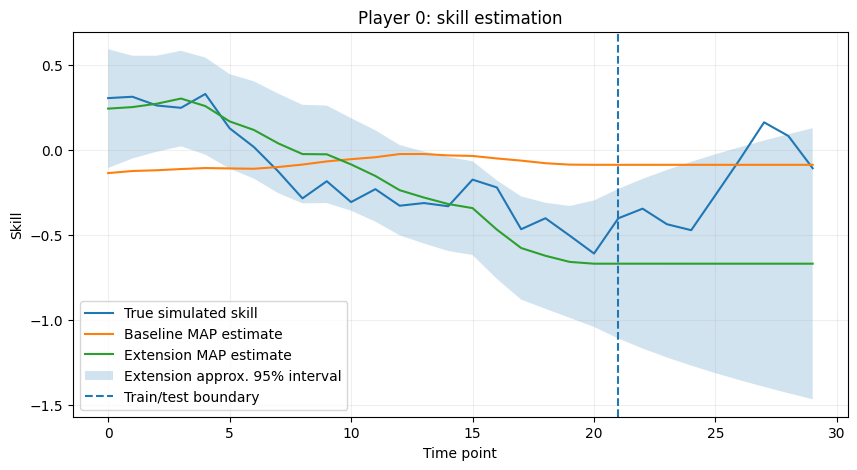

In [7]:
import matplotlib.pyplot as plt
import numpy as np

p = 0
ts = np.arange(N_TIMES)

plt.figure(figsize=(10,5))
plt.plot(ts, truth[:,p], label="True simulated skill")
plt.plot(ts, baseline_mu[:,p], label="Baseline MAP estimate")
plt.plot(ts, extension_mu[:,p], label="Extension MAP estimate")

plt.fill_between(
    ts,
    extension_mu[:,p] - 1.96*extension_sd[:,p],
    extension_mu[:,p] + 1.96*extension_sd[:,p],
    alpha=0.2,
    label="Extension approx. 95% interval"
)

plt.axvline(cut, linestyle="--", label="Train/test boundary")
plt.xlabel("Time point")
plt.ylabel("Skill")
plt.title(f"Player {p}: skill estimation")
plt.legend()
plt.grid(alpha=0.2)
os.makedirs("Limitation_Solution_Results", exist_ok=True)

plt.savefig(
    "Limitation_Solution_Results/player0_skill_estimation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 8. Export technical foundation results

In [8]:
os.makedirs("Limitation_Solution_Results",exist_ok=True)
matches.to_csv("Limitation_Solution_Results/synthetic_doubles_data.csv",index=False)
comparison.to_csv("Limitation_Solution_Results/skill_comparison.csv",index=False)
pd.DataFrame([
 {"Model":"Baseline","Log-loss":base_ll,"Brier":base_br,"Runtime":None},
 {"Model":"Extension","Log-loss":ext_ll,"Brier":ext_br,"Runtime":None}
]).to_csv("Limitation_Solution_Results/prediction_comparison.csv",index=False)
print("Saved technical foundation results.")

Saved technical foundation results.


## Interpretation and limitation
This experiment checks whether individual observations can improve recovery of simulated individual skills. The observations are generated from latent skill plus Gaussian noise, so they are informative by construction. Results must not be described as validation on real tennis statistics. The next notebook performs multi-seed M3 evaluation, robustness analysis and statistical testing.